<H1>RL_Network</H1> 
Figure out why we have a divide by zero in an R-L network. 
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 06-Mar-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Circuit.html"> Example circuits </a><br> 
<a href = "https://onlinelibrary.wiley.com/doi/10.1002/mop.10983"> Microwave S-Parameter reduction </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Media.html"> RG58 example </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/api/media/generated/skrf.media.coaxial.Coaxial.html"> Coaxial </a><br>

<H2> Notes </H2>


In [1]:
# imports - package libraries etc. 
import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
from skrf import Network
from skrf import Frequency
from skrf.circuit import Circuit
from skrf.tlineFunctions import INF
#
# skrf figure styling
rf.stylely()

In [12]:
# https://scikit-rf.readthedocs.io/en/v1.8.0/examples/circuit/Lumped%20Element%20Circuits.html
# Define my components here. 
# Frequency domain
scan_frequency = rf.Frequency(7.0, 64.0, 101, 'mhz')
# create a resistor
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.circuit.Circuit.SeriesImpedance.html
R0 = Circuit.SeriesImpedance(scan_frequency, INF, name='R0', z0=50.0)
#
R_val = 75.0 # ohms
R1 = Circuit.SeriesImpedance(scan_frequency, INF , name ='R1', z0=R_val)  # real ohms
# Create inductor too. 
L = 71.3e-9 # henries
#Z  = np.zeros(len(scan_frequency),dtype=complex)
# put a j on the 2 to make it complex.
L1_X = 2.0j *np.pi*scan_frequency.f * L
L1 = Circuit.SeriesImpedance(scan_frequency, INF, name = 'L1', z0=L1_X) 
# Capacitor not used, here as placeholder
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.circuit.Circuit.ShuntAdmittance.html
C1 = Circuit.ShuntAdmittance(scan_frequency, INF, name = 'C1', z0=1j * 2 * np.pi * scan_frequency.f * 1e-12) # 1 pF shunt capacitor
#
# define inductor with finite resistance. 
# 
RL = 1.0e-3
ZL  = np.ones(len(scan_frequency),dtype=complex) * RL
XL = 71.3j * 2 * np.pi * scan_frequency.f * 1e-9
ZL = ZL + XL
Z0_2 = XL * 2 * np.pi * scan_frequency.f * 1e-9
L2 = Circuit.SeriesImpedance(scan_frequency, INF, name = 'L1', z0=Z0_2) # 71.3 nH inductor with finite resistance
#
# What does it mean to design a port? 
# https://scikit-rf.readthedocs.io/en/v1.8.0/api/generated/skrf.circuit.Circuit.Port.html
#
port1  = Circuit.Port(frequency=scan_frequency, name='P1', z0=50)
port2  = Circuit.Port(frequency=scan_frequency, name='P2', z0=50)
ground = Circuit.Ground(scan_frequency, name='ground')

Trying to figure out why an R-L circuit has a divide by zero and then issues a bunch of NaN in calculations. 
<ul>
    <li> 2 resistors in the network is fine and behaves correcty. </li> 
    <li> The resistor and an inductor of zero real value gives a NaN. </li>  
    <li> The resistor and an inductor of non-zero real value also gives a NaN. </li>  
</ul>

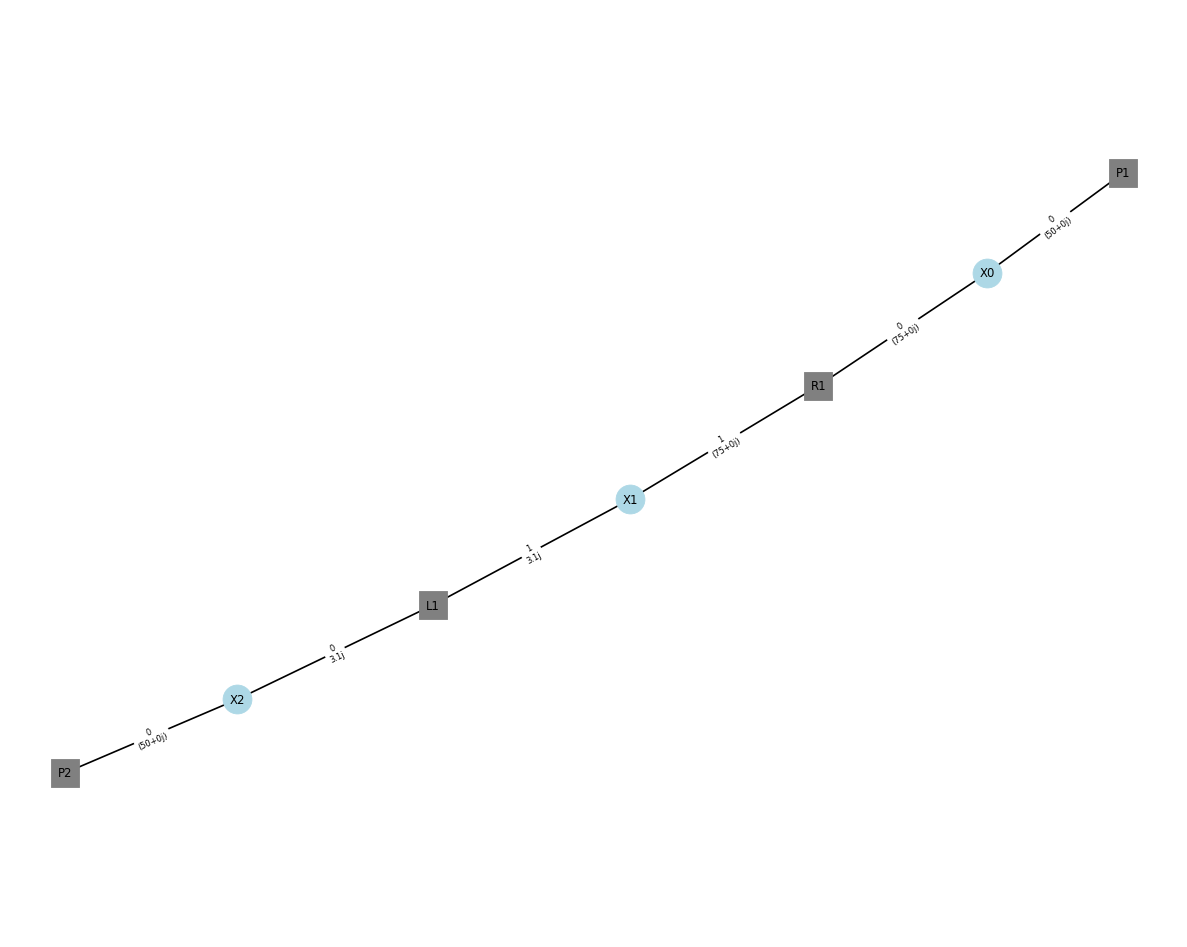

In [3]:
# R-L circuit
connections = [
    [(port1, 0), (R1, 0)],
    [(R1, 1), (L1,1)],
    [(L1, 0), (port2, 0)]
]
circuit = Circuit(connections)
#LC_from_circuit = circuit.network
#
# Draw the resulting graph
#
circuit.plot_graph(network_labels=True,edge_labels=True,port_labels=True,inter_labels=True)

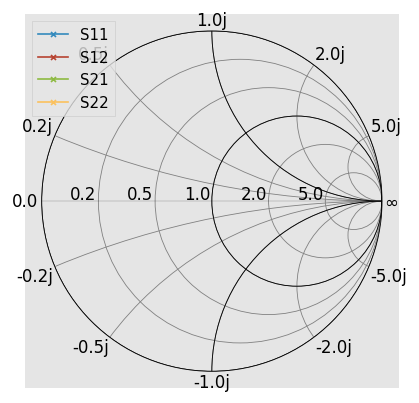

In [11]:
# show the smith chart for the above. 
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.network.Network.plot_s_smith.html
circuit.network.plot_s_smith(draw_labels=True,marker='x')

In [12]:
circuit.network.s[:11,0,1]

array([nan+nanj, nan+nanj, nan+nanj, nan+nanj, nan+nanj, nan+nanj,
       nan+nanj, nan+nanj, nan+nanj, nan+nanj, nan+nanj])